# Exploratory Data Analysis

## Objective

Explore the distributions of the target variable and selected features to understand the dataset before preparing it for machine learning.

This analysis will help identify class imbalance, unusual feature distributions, and variables that need special treatment during preprocessing.

In [3]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent
data_path = project_root / "data" / "raw" / "data.csv"

df = pd.read_csv(data_path, sep=";")
df.columns = df.columns.str.strip()

df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


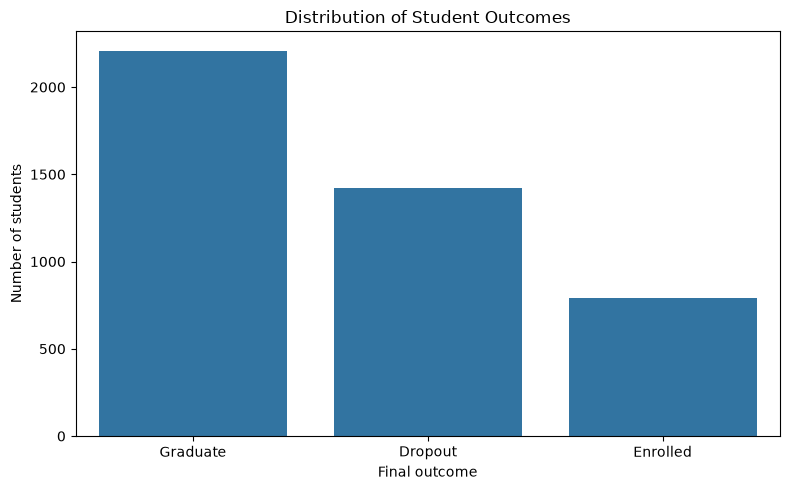

In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Target",
    order=df["Target"].value_counts().index
)

plt.title("Distribution of Student Outcomes")
plt.xlabel("Final outcome")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

### Target Distribution

The target variable contains three outcome classes: Graduate (2,209 students; 49.93%), Dropout (1,421; 32.12%), and Enrolled (794; 17.95%).

Graduate is the most frequent outcome, while Enrolled is the least frequent. This class imbalance means that accuracy alone may not provide a complete picture of model performance. We will also evaluate macro-F1 and recall for each class.

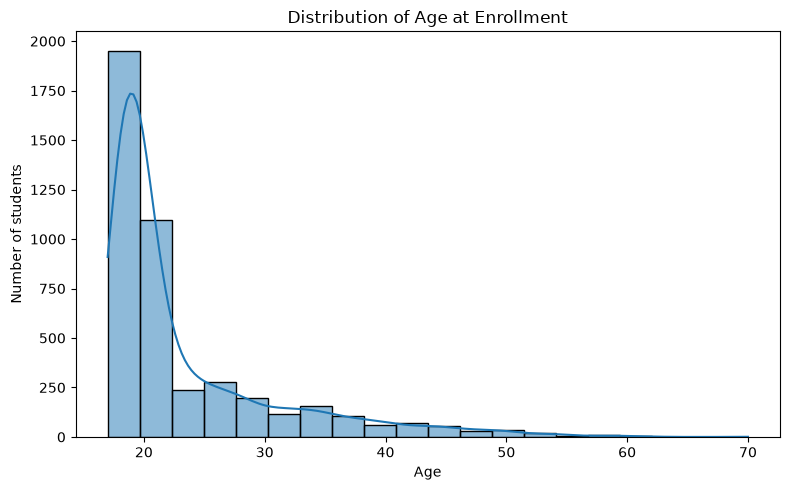

In [5]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age at enrollment",
    bins=20,
    kde=True
)

plt.title("Distribution of Age at Enrollment")
plt.xlabel("Age")
plt.ylabel("Number of students")
plt.tight_layout()

plt.show()

### Age at Enrollment

The age distribution peaks around age 20, after which the number of students decreases noticeably through the mid-20s. The distribution appears right-skewed, with fewer students at older ages.

This suggests that the dataset contains more students entering higher education at younger ages, alongside a smaller group of older students. The histogram describes the overall age distribution; it does not by itself show whether age is associated with the final academic outcome.

In [6]:
semester_columns = [
    col for col in df.columns
    if "1st sem" in col.lower()
    or "2nd sem" in col.lower()
]

print("Semester-related columns:")
for col in semester_columns:
    print(col)

Semester-related columns:
Curricular units 1st sem (credited)
Curricular units 1st sem (enrolled)
Curricular units 1st sem (evaluations)
Curricular units 1st sem (approved)
Curricular units 1st sem (grade)
Curricular units 1st sem (without evaluations)
Curricular units 2nd sem (credited)
Curricular units 2nd sem (enrolled)
Curricular units 2nd sem (evaluations)
Curricular units 2nd sem (approved)
Curricular units 2nd sem (grade)
Curricular units 2nd sem (without evaluations)


### Identifying Post-Enrollment Features

The dataset contains 12 semester-related features describing curricular units and academic performance during the first and second semesters.

These features are not available at the time of enrollment. Including them in an enrollment-time prediction model would introduce temporal data leakage because the model would use information recorded after the prediction point.

We will exclude these features from the enrollment-time model while retaining the original dataset unchanged.

In [7]:
# List candidate features outside the semester-related columns.
candidate_columns = [
    col for col in df.columns
    if col not in semester_columns and col != "Target"
]

print("Number of candidate features:", len(candidate_columns))

for col in candidate_columns:
    print(col)

Number of candidate features: 24
Marital status
Application mode
Application order
Course
Daytime/evening attendance
Previous qualification
Previous qualification (grade)
Nacionality
Mother's qualification
Father's qualification
Mother's occupation
Father's occupation
Admission grade
Displaced
Educational special needs
Debtor
Tuition fees up to date
Gender
Scholarship holder
Age at enrollment
International
Unemployment rate
Inflation rate
GDP


### Preliminary Feature Review

The 24 candidate features describe student demographics, educational background, admission details, financial circumstances, and economic context.

Before modeling, each feature must be reviewed to determine whether it is available at enrollment and whether its values represent numerical measurements, ordered categories, or nominal categories.

The 12 semester-related features have been excluded from the planned enrollment-time prediction task because they contain information recorded after enrollment. The original dataset remains unchanged.

Some features, including tuition-fee status, debtor status, scholarship status, and economic indicators, require further verification before the final feature list is established.

In [8]:
for col in candidate_columns:
    print(f"\n{col}")
    print("Number of unique values:", df[col].nunique())
    print("Example values:", df[col].unique()[:10])


Marital status
Number of unique values: 6
Example values: [1 2 4 3 5 6]

Application mode
Number of unique values: 18
Example values: [17 15  1 39 18 53 44 51 43  7]

Application order
Number of unique values: 8
Example values: [5 1 2 4 3 6 9 0]

Course
Number of unique values: 17
Example values: [ 171 9254 9070 9773 8014 9991 9500 9238 9670 9853]

Daytime/evening attendance
Number of unique values: 2
Example values: [1 0]

Previous qualification
Number of unique values: 17
Example values: [ 1 19 42 39 10  3 40  2  4 12]

Previous qualification (grade)
Number of unique values: 101
Example values: [122.  160.  100.  133.1 142.  119.  137.  138.  139.  136. ]

Nacionality
Number of unique values: 21
Example values: [  1  62   6  41  26 103  13  25  21 101]

Mother's qualification
Number of unique values: 29
Example values: [19  1 37 38  3  4 42  2 34 12]

Father's qualification
Number of unique values: 34
Example values: [12  3 37 38  1 19  5  4 34  2]

Mother's occupation
Number of uni

In [9]:
feature_summary = pd.DataFrame({
    "Data type": df[candidate_columns].dtypes.astype(str),
    "Unique values": df[candidate_columns].nunique(),
    "Example values": [
        df[col].unique()[:8].tolist()
        for col in candidate_columns
    ]
})

display(feature_summary)

,Data type,Unique values,Example values
Marital status,int64,6,"[1, 2, 4, 3, 5, 6]"
Application mode,int64,18,"[17, 15, 1, 39, 18, 53, 44, 51]"
Application order,int64,8,"[5, 1, 2, 4, 3, 6, 9, 0]"
Course,int64,17,"[171, 9254, 9070, 9773, 8014, 9991, 9500, 9238]"
Daytime/evening attendance,int64,2,"[1, 0]"
Previous qualification,int64,17,"[1, 19, 42, 39, 10, 3, 40, 2]"
Previous qualification (grade),float64,101,"[122.0, 160.0, 100.0, 133.1, 142.0, 119.0, 137..."
Nacionality,int64,21,"[1, 62, 6, 41, 26, 103, 13, 25]"
Mother's qualification,int64,29,"[19, 1, 37, 38, 3, 4, 42, 2]"
Father's qualification,int64,34,"[12, 3, 37, 38, 1, 19, 5, 4]"


In [10]:
# Numerical measurements identified from the data dictionary
numerical_columns = [
    "Previous qualification (grade)",
    "Admission grade",
    "Age at enrollment",
    "Unemployment rate",
    "Inflation rate",
    "GDP",
]

# Categorical features represented by integer codes
categorical_columns = [
    "Marital status",
    "Application mode",
    "Course",
    "Daytime/evening attendance",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation",
    "Displaced",
    "Educational special needs",
    "Debtor",
    "Tuition fees up to date",
    "Gender",
    "Scholarship holder",
    "International",
]

print("Numerical features:", len(numerical_columns))
print("Categorical or binary features:", len(categorical_columns))
print("Total features grouped:", len(numerical_columns) + len(categorical_columns))

Numerical features: 6
Categorical or binary features: 17
Total features grouped: 23


In [12]:
print("Numerical columns missing from dataset:")
print([col for col in numerical_columns if col not in df.columns])

print("\nCategorical columns missing from dataset:")
print([col for col in categorical_columns if col not in df.columns])

print("\nCandidate features not yet grouped:")
print([
    col for col in candidate_columns
    if col not in numerical_columns and col not in categorical_columns
])

Numerical columns missing from dataset:
[]

Categorical columns missing from dataset:
[]

Candidate features not yet grouped:
['Application order']
